In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import pandas as pd
from sklearn.linear_model import LogisticRegression

from src.data import load_raw, add_target, get_X_y
from src.preprocessing import build_pipeline, get_feature_types
from src.config import RANDOM_STATE, N_SPLITS

df = add_target(load_raw("por"))
X, y = get_X_y(df, "a_no_grades")   # start with the hardest, most useful scenario
print("X:", X.shape, "| y:", y.shape)

X: (649, 30) | y: (649,)


In [2]:
pipe = build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"), X)

# Fit ONLY the preprocessing step, just to inspect its output
X_ready = pipe.named_steps["prep"].fit_transform(X)
feature_names = pipe.named_steps["prep"].get_feature_names_out()

num_cols, cat_cols = get_feature_types(X)
print(f"Raw features: {X.shape[1]}  ({len(num_cols)} numeric + {len(cat_cols)} categorical)")
print(f"After preprocessing: {X_ready.shape[1]} columns\n")
print("Example new column names:", list(feature_names[13:22]))

# Check the scaling worked: numeric columns should have mean ~0, std ~1
pd.DataFrame(X_ready[:, :len(num_cols)], columns=num_cols).describe().loc[["mean", "std"]].round(2)

Raw features: 30  (13 numeric + 17 categorical)
After preprocessing: 43 columns

Example new column names: ['school_MS', 'sex_M', 'address_U', 'famsize_LE3', 'Pstatus_T', 'Mjob_at_home', 'Mjob_health', 'Mjob_other', 'Mjob_services']


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences
mean,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Stratified = every fold keeps the same ~15% fail ratio as the full data
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

scores = cross_validate(pipe, X, y, cv=cv, scoring=["recall", "f1", "roc_auc"])

for metric in ["recall", "f1", "roc_auc"]:
    s = scores[f"test_{metric}"]
    print(f"{metric:8}: {s.mean():.3f}  (± {s.std():.3f} across {N_SPLITS} folds)")

recall  : 0.670  (± 0.150 across 5 folds)
f1      : 0.465  (± 0.074 across 5 folds)
roc_auc : 0.793  (± 0.060 across 5 folds)


In [4]:
from src.evaluate import evaluate_all

results = evaluate_all(df)

# Save so later stages (and the README) can use the numbers without re-running
reports_dir = ROOT / "reports"
results.to_csv(reports_dir / "cv_results.csv", index=False)

done: a_no_grades  | Baseline (majority)
done: a_no_grades  | Logistic Regression
done: a_no_grades  | Random Forest
done: a_no_grades  | Gradient Boosting
done: b_G1_only    | Baseline (majority)
done: b_G1_only    | Logistic Regression
done: b_G1_only    | Random Forest
done: b_G1_only    | Gradient Boosting
done: c_G1_G2      | Baseline (majority)
done: c_G1_G2      | Logistic Regression
done: c_G1_G2      | Random Forest
done: c_G1_G2      | Gradient Boosting


In [5]:
metrics = ["fail_recall", "fail_precision", "fail_f1", "roc_auc", "pr_auc"]

# Format each metric as "mean ± std" for a readable table
table = results[["scenario", "model"]].copy()
for m in metrics:
    table[m] = results[m].map("{:.2f}".format) + " ± " + results[f"{m}_std"].map("{:.2f}".format)

table.set_index(["scenario", "model"])

fail_recall fail_precision      fail_f1  \
scenario    model                                                          
a_no_grades Baseline (majority)  0.00 ± 0.00    0.00 ± 0.00  0.00 ± 0.00   
            Logistic Regression  0.66 ± 0.13    0.35 ± 0.05  0.46 ± 0.07   
            Random Forest        0.58 ± 0.14    0.39 ± 0.04  0.46 ± 0.07   
            Gradient Boosting    0.51 ± 0.09    0.40 ± 0.04  0.44 ± 0.05   
b_G1_only   Baseline (majority)  0.00 ± 0.00    0.00 ± 0.00  0.00 ± 0.00   
            Logistic Regression  0.86 ± 0.09    0.51 ± 0.01  0.64 ± 0.02   
            Random Forest        0.74 ± 0.10    0.64 ± 0.05  0.68 ± 0.06   
            Gradient Boosting    0.79 ± 0.12    0.59 ± 0.11  0.66 ± 0.07   
c_G1_G2     Baseline (majority)  0.00 ± 0.00    0.00 ± 0.00  0.00 ± 0.00   
            Logistic Regression  0.88 ± 0.07    0.59 ± 0.04  0.71 ± 0.03   
            Random Forest        0.87 ± 0.07    0.64 ± 0.08  0.73 ± 0.05   
            Gradient Boosting    0.83 ± 0.07    0.62 ± 0.05  0.70 ± 0.02   

                                     roc_auc       pr_auc  
scenario    model                                          
a_no_grades Baseline (majority)  0.50 ± 0.00  0.15 ± 0.00  
            Logistic Regression  0.79 ± 0.06  0.44 ± 0.08  
            Random Forest        0.83 ± 0.04  0.50 ± 0.07  
            Gradient Boosting    0.79 ± 0.03  0.48 ± 0.08  
b_G1_only   Baseline (majority)  0.50 ± 0.00  0.15 ± 0.00  
            Logistic Regression  0.93 ± 0.01  0.69 ± 0.07  
            Random Forest        0.94 ± 0.02  0.71 ± 0.06  
            Gradient Boosting    0.94 ± 0.02  0.71 ± 0.08  
c_G1_G2     Baseline (majority)  0.50 ± 0.00  0.15 ± 0.00  
            Logistic Regression  0.96 ± 0.01  0.81 ± 0.03  
            Random Forest        0.97 ± 0.01  0.83 ± 0.06  
            Gradient Boosting    0.96 ± 0.02  0.86 ± 0.02

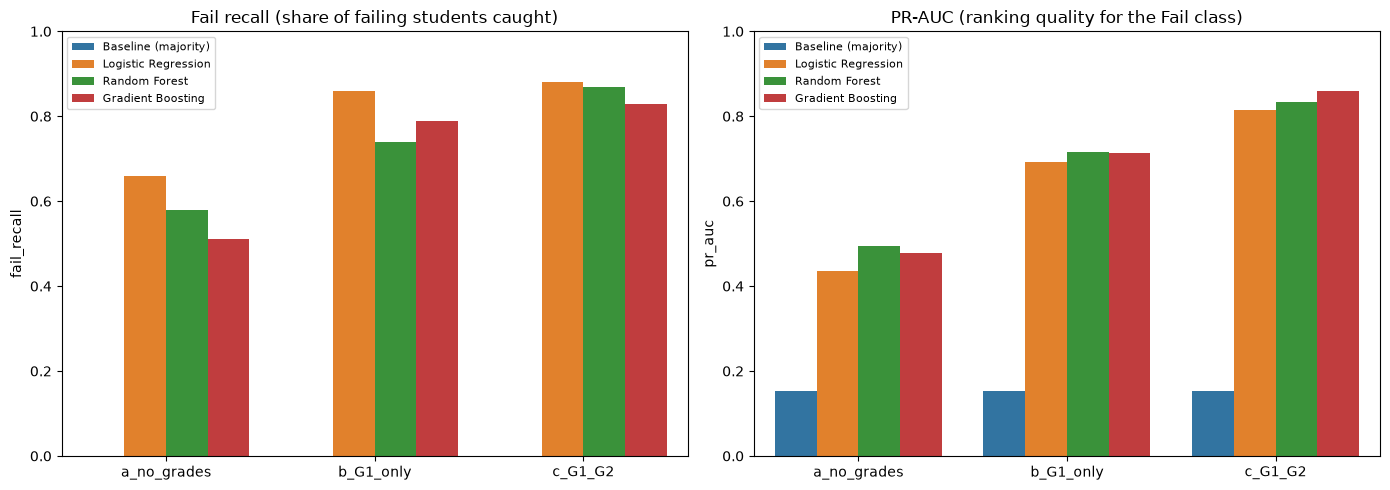

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import FIGURES_DIR

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, metric, title in zip(axes, ["fail_recall", "pr_auc"],
                             ["Fail recall (share of failing students caught)",
                              "PR-AUC (ranking quality for the Fail class)"]):
    sns.barplot(data=results, x="scenario", y=metric, hue="model", ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylim(0, 1)
    ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_model_comparison.png", dpi=150)
plt.show()

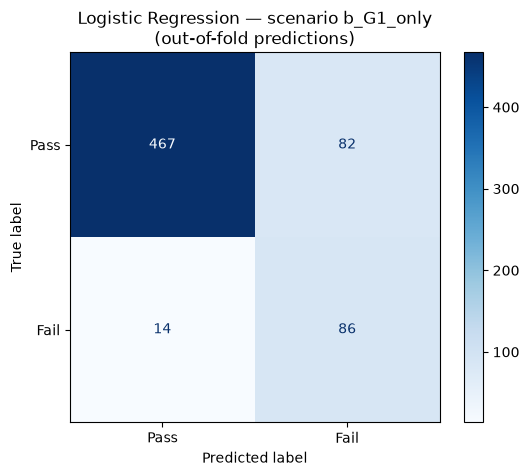

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
from src.models import get_models
from src.evaluate import make_estimator, get_cv

SCENARIO = "b_G1_only"
MODEL = "Logistic Regression"

X_b, y_b = get_X_y(df, SCENARIO)
model, scale, grid = get_models()[MODEL]
y_pred = cross_val_predict(make_estimator(model, scale, grid, X_b), X_b, y_b, cv=get_cv())

disp = ConfusionMatrixDisplay.from_predictions(
    y_b, y_pred, display_labels=["Pass", "Fail"], cmap="Blues")
disp.ax_.set_title(f"{MODEL} — scenario {SCENARIO}\n(out-of-fold predictions)")
plt.savefig(FIGURES_DIR / "09_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()